In [2]:
import pickle
import numpy as np
import random
import matplotlib.pyplot as plt  # 添加这行导入

from sklearn.preprocessing import StandardScaler
import umap

# 固定所有随机种子为42（确保实验可复现）
random.seed(42)       # Python内置随机模块
np.random.seed(42)    # NumPy随机数生成

## 读取书数据
with open("/home/baolingjie/git_download/NMR_Core_Mol_Detection/data/enumerate_100m_5m_1_group_restricted/last_results.pkl", "rb") as f:
    data = pickle.loads(f.read())

## 过滤数据
count = 0
for _ in data:
    if len(list(set(_["C_nmr"])))>0:
        count = count + 1
print(f"len(data):{len(data)}, count:{count}")
data_ = [_ for _ in data if len(list(set(_["C_nmr"])))>0]
data_ = random.sample(data_, min(20000, len(data_))) #100000


## 命名
query_dict = {
    # 'alkene': 5,
    'alcohol': 2,
    'amide': 10,
    'ester': 37,
    # 'ketone': 50,
    'sulfide': 80,
    'ether': 38,
    'pyridyl': 72,
    'hydrocarbon': 41,
    'amine': 12,
    'sulfone': 83,
    'aldehyde': 3,
    'polyol': 68,
    'nitro': 56,
    #  'secondary_amine': 76,
    'haloalkane': 40,
    #  'alkyne': 9,
    #  'tertiary_amine': 86
}

query_name = [v for v in query_dict.keys()]
query_list = [v for v in query_dict.values()]
print(f"query_name:{query_name}, query_list:{query_list}")

## 计算
labels = [query_name[list(_["function_list"][query_list]).index(1)] for _ in data_]
function_array = np.array([_["function_list"] for _ in data_])
function_array = function_array[:,query_list]

print(f"labels:{len(labels)}, function_array:{function_array.shape}")

# 参数设置
SHIFT_RANGE = (-10, 230)  # 化学位移有效范围
BIN_SIZE = 0.5            # 分箱精度（ppm）
N_BINS = int((SHIFT_RANGE[1] - SHIFT_RANGE[0]) / BIN_SIZE) + 1

def chemical_shift_to_fingerprint(shifts, visualize=False):
    """
    将化学位移数组转换为指纹向量
    
    参数:
        shifts (np.array): 化学位移数组
        visualize (bool): 是否打印可视化结果
        
    返回:
        np.array: 指纹向量（二进制）
        dict: 分箱统计结果
    """
    # 1. 截断超出范围的化学位移
    shifts = np.array(shifts)
    clipped = np.clip(shifts, *SHIFT_RANGE)
    
    # 2. 计算每个位移对应的bin索引
    bins = ((clipped - SHIFT_RANGE[0]) / BIN_SIZE).astype(int)
    
    # 3. 生成指纹向量（480维：[-10,230]范围，0.5精度）
    fingerprint = np.zeros(N_BINS, dtype=int)
    unique_bins, counts = np.unique(bins, return_counts=True)
    fingerprint[unique_bins] = 1  # 存在位移的bin标记为1
    
    # 4. 统计信息
    bin_stats = {
        "total_bins": N_BINS,
        "occupied_bins": len(unique_bins),
        "min_shift": round(clipped.min(), 2),
        "max_shift": round(clipped.max(), 2),
        "bin_edges": np.linspace(*SHIFT_RANGE, N_BINS+1)
    }
    
    if visualize:
        print("=== 化学位移指纹转换结果 ===")
        print(f"有效位移范围: {SHIFT_RANGE} ppm")
        print(f"分箱精度: {BIN_SIZE} ppm → 总箱数: {N_BINS}")
        print(f"实际占用箱数: {bin_stats['occupied_bins']}")
        print("\n示例指纹片段（前20个bin）:")
        print(fingerprint[:20])
        
        # 可视化分布
        import matplotlib.pyplot as plt
        plt.figure(figsize=(10, 4))
        plt.hist(clipped, bins=bin_stats['bin_edges'], edgecolor='black')
        plt.title("化学位移分布直方图")
        plt.xlabel("化学位移 (ppm)")
        plt.ylabel("频次")
        plt.grid(alpha=0.3)
        plt.show()
    
    return fingerprint, bin_stats


nmr_fp_array = np.stack([chemical_shift_to_fingerprint(np.array(list(set(_["C_nmr"]))))[0] for _ in data_])



/home/baolingjie/anaconda3/envs/py310_v2/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


len(data):522904, count:522887
query_name:['alcohol', 'amide', 'ester', 'sulfide', 'ether', 'pyridyl', 'hydrocarbon', 'amine', 'sulfone', 'aldehyde', 'polyol', 'nitro', 'haloalkane'], query_list:[2, 10, 37, 80, 38, 72, 41, 12, 83, 3, 68, 56, 40]
labels:20000, function_array:(20000, 13)


In [3]:
# 3. 标准化数据（UMAP对尺度敏感）
scaler = StandardScaler()
scaled_data = scaler.fit_transform(nmr_fp_array)

reducer = umap.UMAP(
    n_components=2,          # 降维到2D
    n_neighbors=15,          # 局部结构的邻居数
    min_dist=0.1,            # 控制点聚集程度
    metric='euclidean',      # 距离度量
    random_state=42,
    # n_jobs=20
)
embedding = reducer.fit_transform(scaled_data)

/home/baolingjie/anaconda3/envs/py310_v2/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/tmp/ipykernel_1337510/2375273783.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = plt.cm.get_cmap('RdYlBu_r', num_categories)  # 也可用 'tab10'（最多10类）
/tmp/ipykernel_1337510/2375273783.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


(np.float64(-7.637920784950256),
 np.float64(26.86036102771759),
 np.float64(-12.319834327697754),
 np.float64(23.29023609161377))

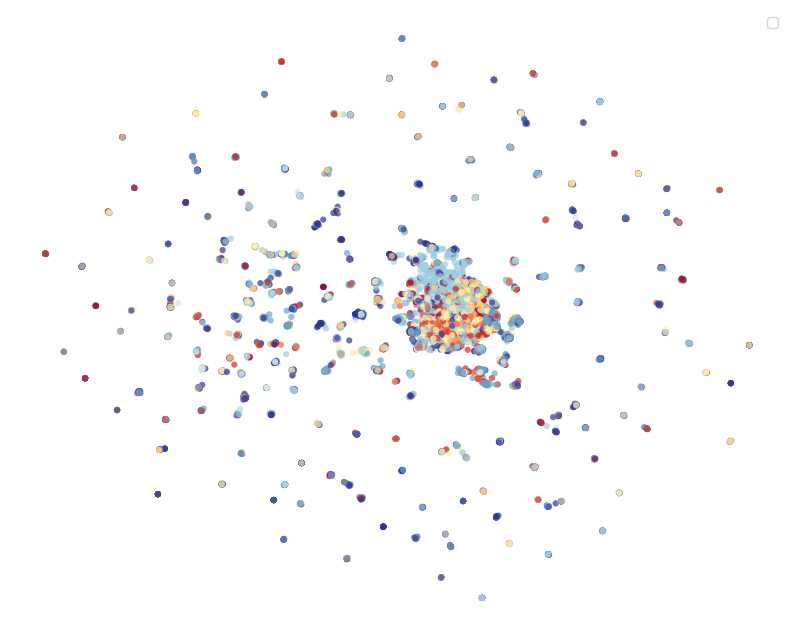

In [4]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
numeric_labels = label_encoder.fit_transform(labels)  # 转换为0,1,2,...

# 2. 创建颜色映射
unique_labels = np.unique(labels)
num_categories = len(unique_labels)
colormap = plt.cm.get_cmap('RdYlBu_r', num_categories)  # 也可用 'tab10'（最多10类）

# 3. 绘制散点图
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    embedding[:, 0], 
    embedding[:, 1],
    c=numeric_labels,          # 使用数值标签
    cmap=colormap,             # 颜色映射
    alpha=0.7,                # 透明度
    s=20,                     # 点大小
    edgecolor='none'           # 完全无边框
)

# 4. 添加颜色条
# cbar = plt.colorbar(scatter)
# cbar.set_ticks(range(num_categories))  # 设置刻度位置
# cbar.set_ticklabels(unique_labels)      # 设置刻度标签
# cbar.set_label('Functional Group', rotation=270, labelpad=15)

# 5. 添加标题和标签
# plt.title("Chemical Fingerprint UMAP Projection", fontsize=14)
# plt.xlabel("UMAP Dimension 1", fontsize=12)
# plt.ylabel("UMAP Dimension 2", fontsize=12)
plt.legend()

plt.axis('off')
# plt.grid(alpha=0.2)

In [5]:
from sklearn.decomposition import PCA
# PCA降维
reducer = PCA(
    n_components=2,          # 降维到2D
    random_state=42
)
embedding = reducer.fit_transform(scaled_data)

/tmp/ipykernel_1337510/3120150792.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = plt.cm.get_cmap('RdYlBu_r', num_categories)  # 也可用 'tab10'（最多10类）
/tmp/ipykernel_1337510/3120150792.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


(np.float64(-11.171814143359981),
 np.float64(12.927282898010779),
 np.float64(-4.845456718895462),
 np.float64(10.92227365705178))

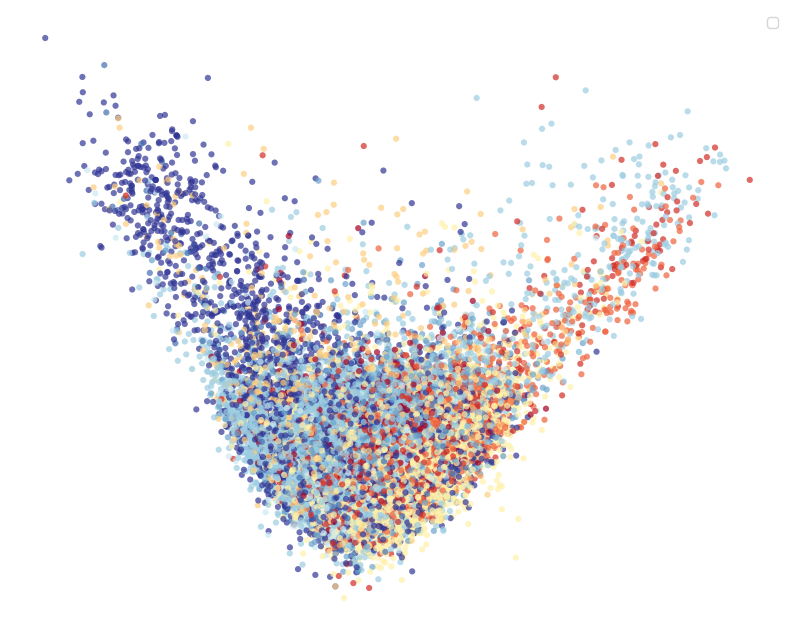

In [7]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
numeric_labels = label_encoder.fit_transform(labels)  # 转换为0,1,2,...

# 2. 创建颜色映射
unique_labels = np.unique(labels)
num_categories = len(unique_labels)
colormap = plt.cm.get_cmap('RdYlBu_r', num_categories)  # 也可用 'tab10'（最多10类）

# 3. 绘制散点图
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    embedding[:, 0], 
    embedding[:, 1],
    c=numeric_labels,          # 使用数值标签
    cmap=colormap,             # 颜色映射
    alpha=0.7,                # 透明度
    s=20,                     # 点大小
    edgecolor='none'           # 完全无边框
)

# 4. 添加颜色条
# cbar = plt.colorbar(scatter)
# cbar.set_ticks(range(num_categories))  # 设置刻度位置
# cbar.set_ticklabels(unique_labels)      # 设置刻度标签
# cbar.set_label('Functional Group', rotation=270, labelpad=15)

# 5. 添加标题和标签
# plt.title("Chemical Fingerprint UMAP Projection", fontsize=14)
# plt.xlabel("UMAP Dimension 1", fontsize=12)
# plt.ylabel("UMAP Dimension 2", fontsize=12)
plt.legend()

plt.axis('off')

In [1]:
from sklearn.manifold import TSNE

reducer = TSNE(
    n_components=2,
    perplexity=30,           # 典型值在5-50之间
    learning_rate='auto',     # 自动调整或设为200
    # n_iter=1000,             # 迭代次数
    random_state=42,
    init='pca',              # 使用PCA初始化
    metric='euclidean'       # 距离度量
)
embedding = reducer.fit_transform(scaled_data)

NameError: name 'scaled_data' is not defined

In [ ]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
numeric_labels = label_encoder.fit_transform(labels)  # 转换为0,1,2,...

# 2. 创建颜色映射
unique_labels = np.unique(labels)
num_categories = len(unique_labels)
colormap = plt.cm.get_cmap('coolwarm', num_categories)  # 也可用 'tab10'（最多10类）

# 3. 绘制散点图
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    embedding[:, 0], 
    embedding[:, 1],
    c=numeric_labels,          # 使用数值标签
    cmap=colormap,             # 颜色映射
    alpha=0.7,                # 透明度
    s=20,                     # 点大小
    edgecolor='none'           # 完全无边框
)

# 4. 添加颜色条
# cbar = plt.colorbar(scatter)
# cbar.set_ticks(range(num_categories))  # 设置刻度位置
# cbar.set_ticklabels(unique_labels)      # 设置刻度标签
# cbar.set_label('Functional Group', rotation=270, labelpad=15)

# 5. 添加标题和标签
# plt.title("Chemical Fingerprint UMAP Projection", fontsize=14)
# plt.xlabel("UMAP Dimension 1", fontsize=12)
# plt.ylabel("UMAP Dimension 2", fontsize=12)
plt.legend()

plt.axis('off')